In [8]:
import numpy as np

from mimopy import AntennaArray, Network
from mimopy.channels import LoS, RicianChannel

from maenv import MIMOMAEnv
from interference_training import SAC_Args

args = SAC_Args()

In [21]:
tx = AntennaArray.ula(
    1, name="tx", array_center=args.tx_coord
)
rx = AntennaArray.ula(
    args.Nr, name="rx", array_center=args.rx_coord
)
ul = AntennaArray.ula(
    args.Nul, name="ul", array_center=args.ul_coord
)
tx.power = args.tx_power
rx.power = args.rx_power
ul.power = args.ul_power
l = LoS(ul, rx, "ul-rx").realize()
si = RicianChannel(tx, rx, K=.1, name="si").realize()
net = Network("DL with Interference")
net.add_links([l, si])
net.add_target_links([l])
net.add_target_nodes([rx])

env = MIMOMAEnv(net, args.target_meas, args.metrics)
env.reset(args.seed)

<Axes: title={'center': 'Elevation = 0 deg, Max Gain = 5.18 dB'}, xlabel='Azimuth (deg)', ylabel='Gain (dB)'>

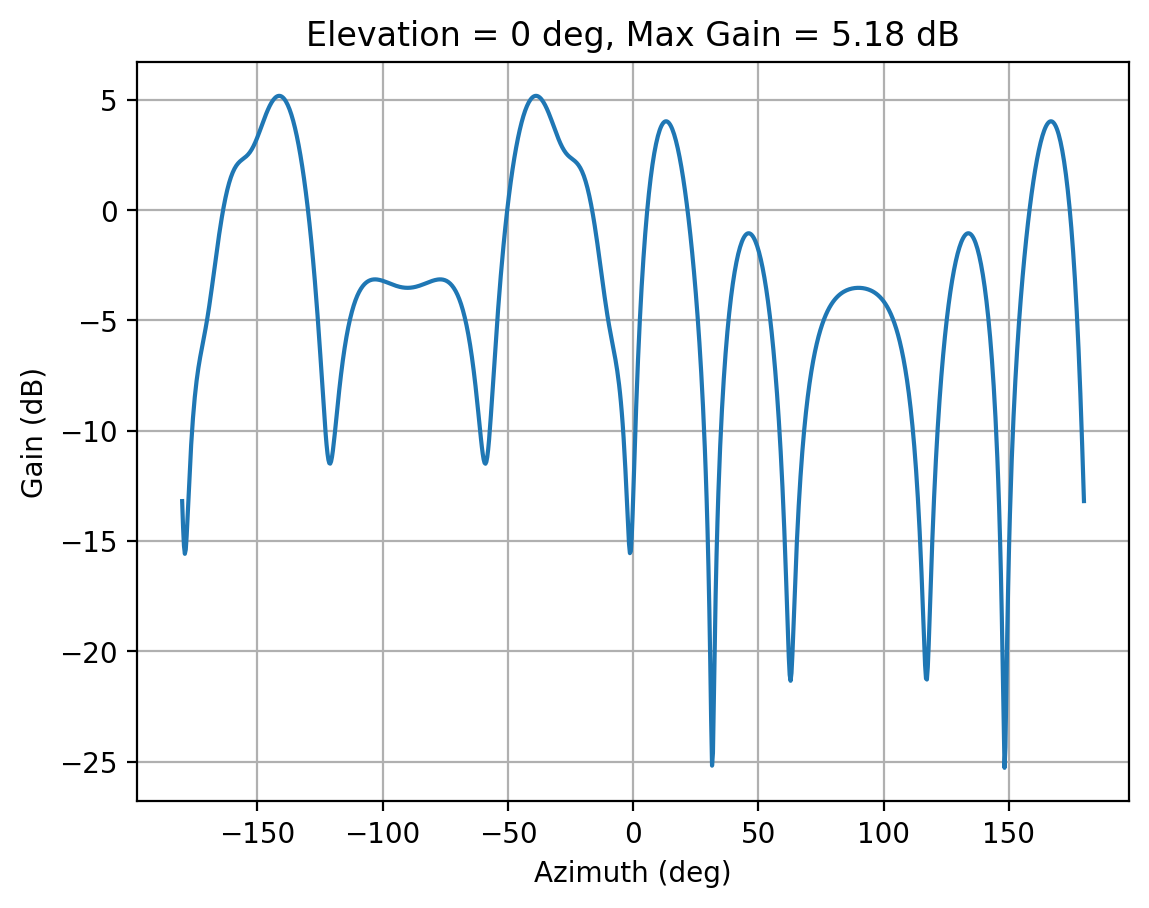

In [22]:
rx.plot_gain(angles=np.linspace(-180, 180, 1000),weights=si.H.conj())

In [27]:
tx.plot_gain()

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 1 is different from 178)

<Axes: title={'center': 'Elevation = 0 deg, Max Gain = 9.03 dB'}, xlabel='Azimuth (deg)', ylabel='Gain (dB)'>

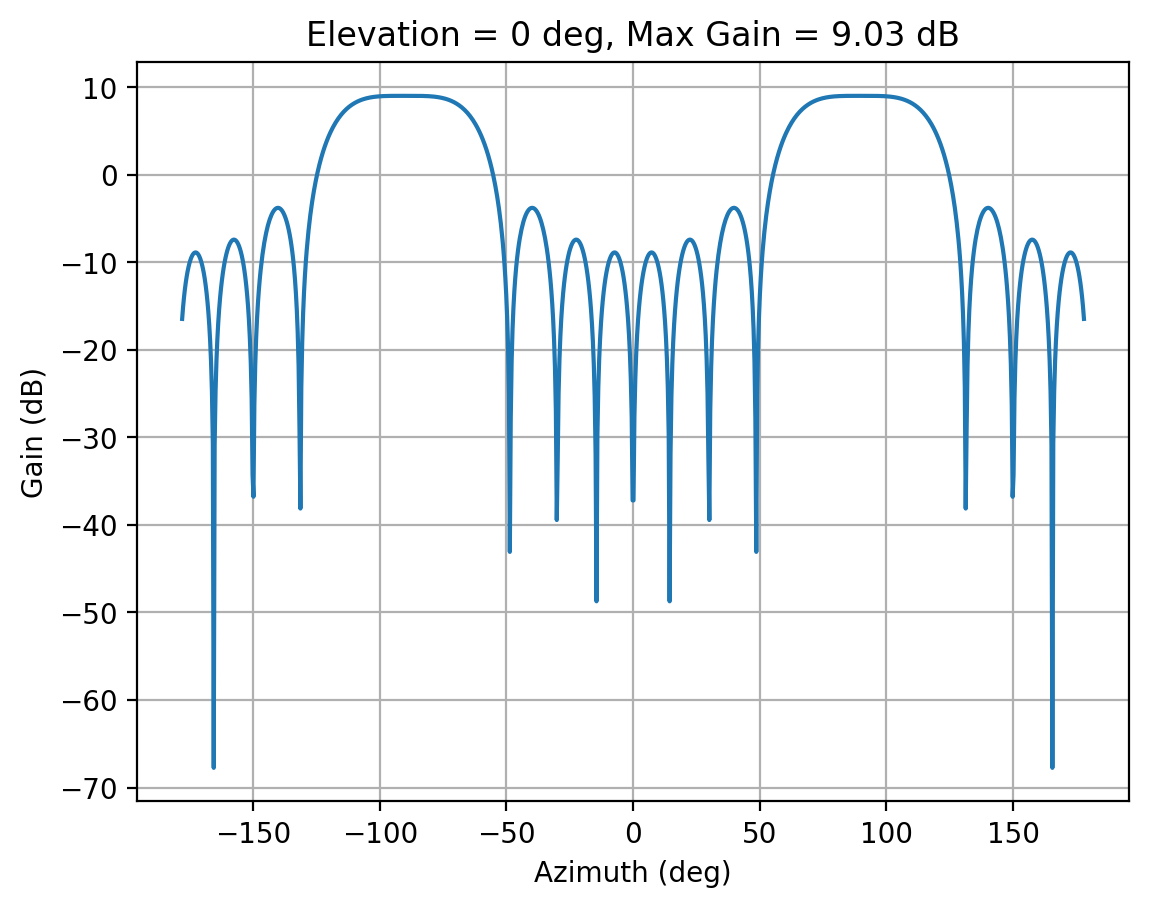

In [16]:
los = LoS(tx, rx).realize()
rx.plot_gain(angles=np.linspace(-178, 178, 1000),weights=los.H.conj())